# 03 — Shift de distribution (Part III)
Sources : `results/shift_*.csv`, `results/photometry_tests.csv`, `results/failure_layers_*.csv`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R, F = ROOT / "results", ROOT / "figures"
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
def fig(name):
    p = F / f"{name}.png"
    display(Image(str(p))) if p.exists() else print("missing figure:", p.name)
def csv(name):
    p = R / name
    return pd.read_csv(p) if p.exists() else print("missing table:", p.name)

In [2]:
for bb in ['vit_s16', 'resnet50']:
    d = csv(f'shift_{bb}.csv')
    display(Markdown(f'**{bb}**'))
    display(d[d.corruption=='clean'][['split','acc','nll','ece']])
    display(d[d.corruption!='clean'].pivot(index='corruption', columns='severity', values='acc'))

**vit_s16**

,split,acc,nll,ece
0,S_test,0.772,0.828,0.047
1,S_hold,0.762,0.916,0.064
2,A_test,0.712,1.088,0.045
3,W_test,0.741,0.997,0.035
4,P_test,0.714,1.011,0.040


severity,1,2,3,4,5
corruption,,,,,
contrast,0.723,0.694,0.649,0.559,0.382
defocus_blur,0.712,0.694,0.623,0.554,0.459
gaussian_noise,0.721,0.682,0.602,0.474,0.316
haze,0.750,0.741,0.724,0.700,0.643
jpeg,0.691,0.633,0.574,0.489,0.330
low_light,0.748,0.721,0.680,0.626,0.518
motion_blur,0.720,0.634,0.550,0.452,0.371
pixelate,0.736,0.697,0.615,0.510,0.356


**resnet50**

,split,acc,nll,ece
0,S_test,0.492,2.086,0.065
1,S_hold,0.454,2.116,0.061
2,A_test,0.446,2.263,0.042
3,W_test,0.453,2.228,0.045
4,P_test,0.457,2.220,0.035


severity,1,2,3,4,5
corruption,,,,,
contrast,0.384,0.321,0.239,0.150,0.080
defocus_blur,0.371,0.345,0.287,0.230,0.164
gaussian_noise,0.311,0.209,0.105,0.047,0.021
haze,0.454,0.400,0.324,0.259,0.178
jpeg,0.361,0.299,0.229,0.145,0.078
low_light,0.356,0.296,0.228,0.168,0.097
motion_blur,0.378,0.281,0.177,0.127,0.089
pixelate,0.323,0.233,0.144,0.096,0.042


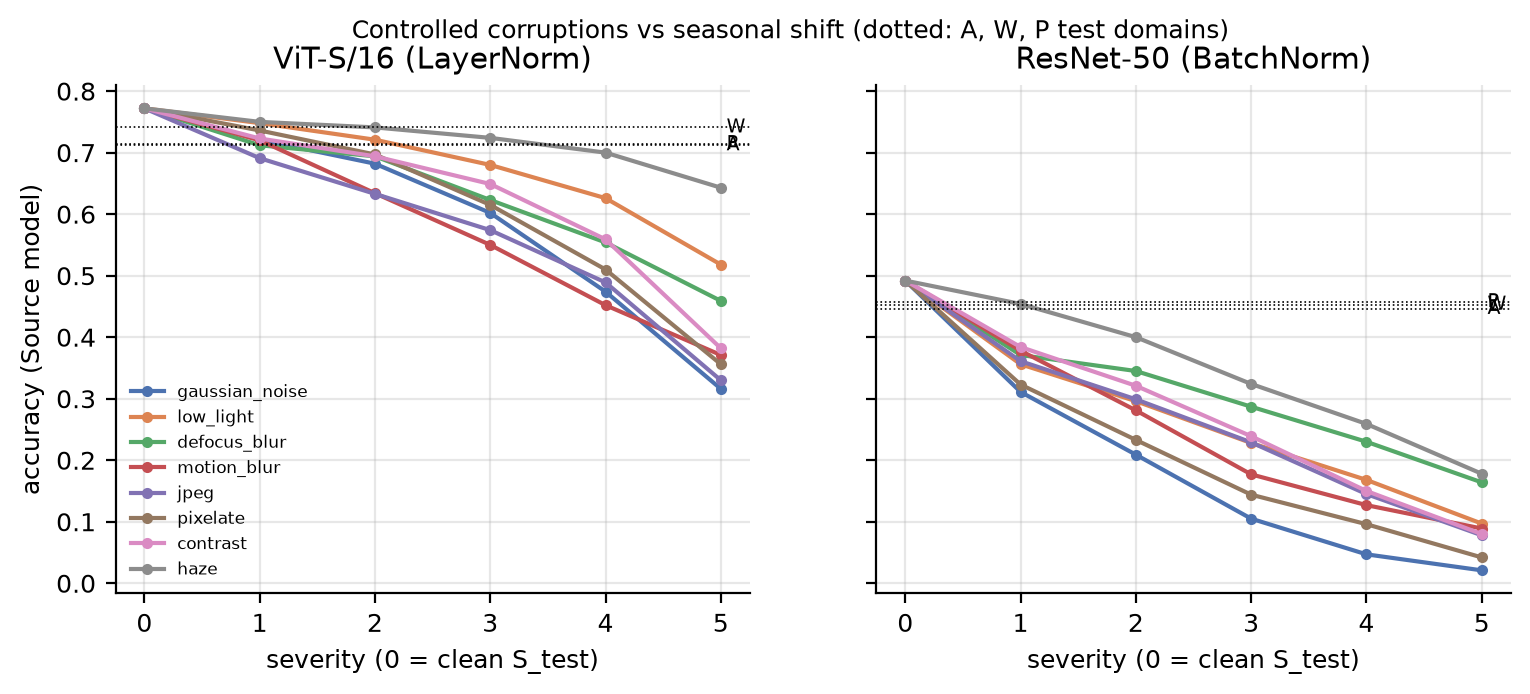

In [3]:
fig('05_shift_severity_curves')

## Pourquoi ? (1) photométrie

In [4]:
t = csv('photometry_tests.csv'); t.pivot(index='stat', columns='target', values='cliffs_delta')

target,A_test:clean,P_test:clean,S_hold:clean,S_test:haze_s3,S_test:low_light_s3,W_test:clean
stat,,,,,,
blue_cast,-0.022,-0.039,-2.243e-02,-0.187,-0.186,-0.075
brightness,0.058,-0.018,-2.568e-02,-0.842,0.946,0.002
colorfulness,0.015,0.028,-1.651e-02,0.653,0.184,0.062
contrast,0.026,0.024,2.685e-02,0.825,0.812,0.017
green_cast,0.046,0.129,4.991e-02,0.263,0.256,0.265
saturation,0.006,0.036,-3.600e-05,0.808,-0.504,0.082
sharpness,-0.027,-0.027,2.328e-02,0.691,-0.061,0.019


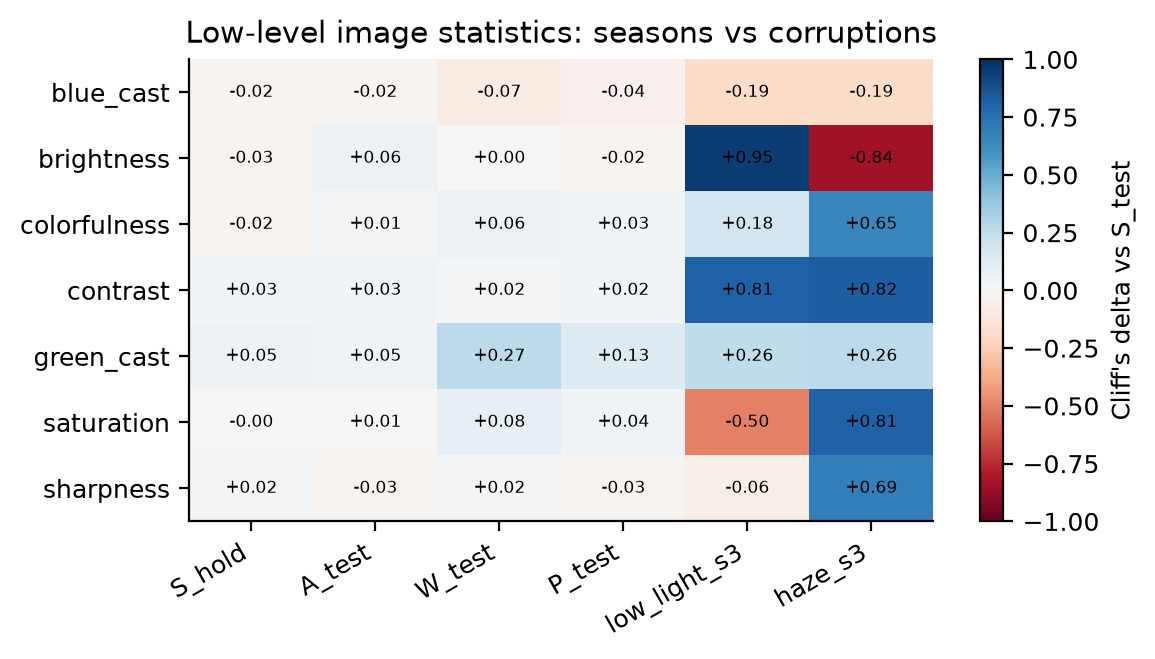

In [5]:
fig('05_why_photometry')

## Pourquoi ? (2) dérive des représentations (référence S_hold = même domaine)

In [6]:
for bb in ['vit_s16', 'resnet50']:
    display(Markdown(f'**{bb}**')); display(csv(f'shift_drift_{bb}.csv'))

**vit_s16**

,split,condition,mmd,cka_to_clean,centroid_shift_ratio
0,S_test,clean,0.000,1.000,0.311
1,S_hold,clean,0.002,NaN,0.554
2,A_test,clean,0.002,NaN,0.567
3,W_test,clean,0.006,NaN,0.585
4,P_test,clean,0.003,NaN,0.557
5,S_test,gaussian_noise_s1,0.080,0.922,0.564
6,S_test,gaussian_noise_s2,0.097,0.876,0.616
7,S_test,gaussian_noise_s3,0.121,0.815,0.685
8,S_test,gaussian_noise_s4,0.157,0.722,0.773
9,S_test,gaussian_noise_s5,0.213,0.593,0.892


**resnet50**

,split,condition,mmd,cka_to_clean,centroid_shift_ratio
0,S_test,clean,0.000,1.000,0.436
1,S_hold,clean,0.001,NaN,0.775
2,A_test,clean,0.001,NaN,0.777
3,W_test,clean,0.003,NaN,0.808
4,P_test,clean,0.001,NaN,0.780
5,S_test,gaussian_noise_s1,0.071,0.734,0.933
6,S_test,gaussian_noise_s2,0.137,0.610,1.180
7,S_test,gaussian_noise_s3,0.211,0.528,1.392
8,S_test,gaussian_noise_s4,0.316,0.465,1.606
9,S_test,gaussian_noise_s5,0.469,0.418,1.847


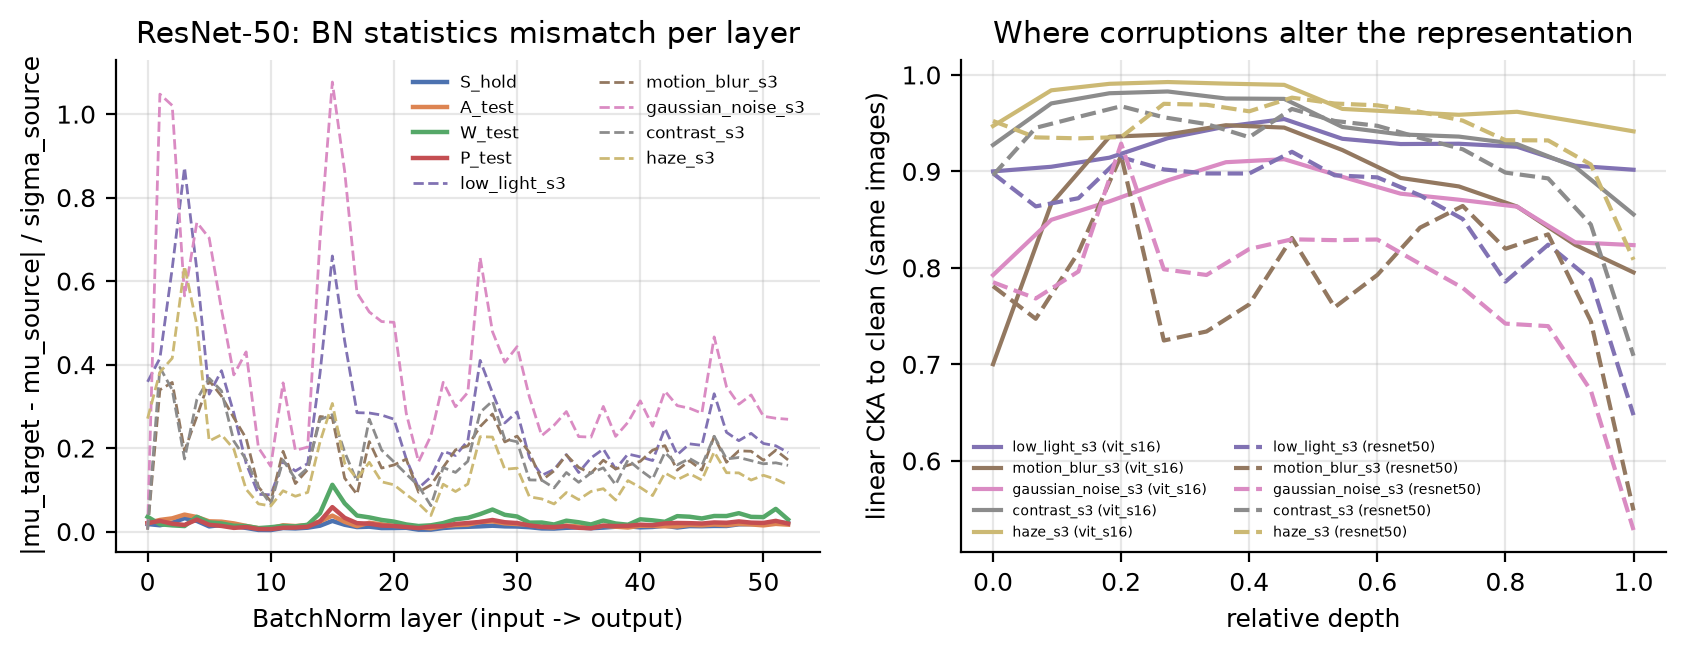

In [7]:
fig('05_why_layers')

## Pourquoi ? (3) structure taxonomique des erreurs

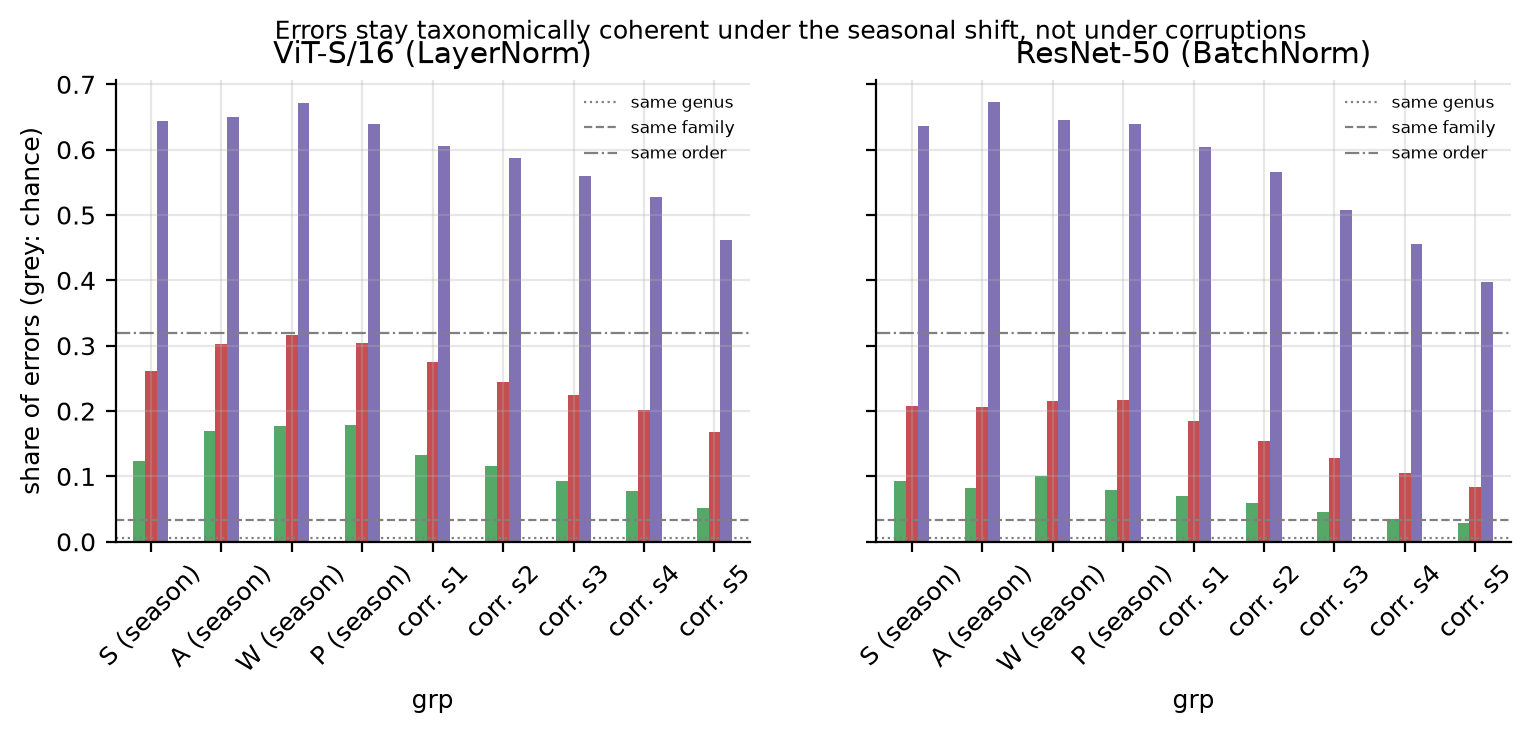

In [8]:
fig('05_why_taxonomy')

## Pourquoi ? (4) chute par espèce vs déplacement migratoire

In [9]:
from scipy import stats
for bb in ['vit_s16', 'resnet50']:
    p = csv(f'shift_species_{bb}.csv'); w = p[p.target=='W'].dropna()
    print(bb, stats.spearmanr(w.displacement_km, w['drop']))

vit_s16 SignificanceResult(statistic=np.float64(0.018224149646989474), pvalue=np.float64(0.8571798891949708))
resnet50 SignificanceResult(statistic=np.float64(0.13755563975018548), pvalue=np.float64(0.17232867633569474))


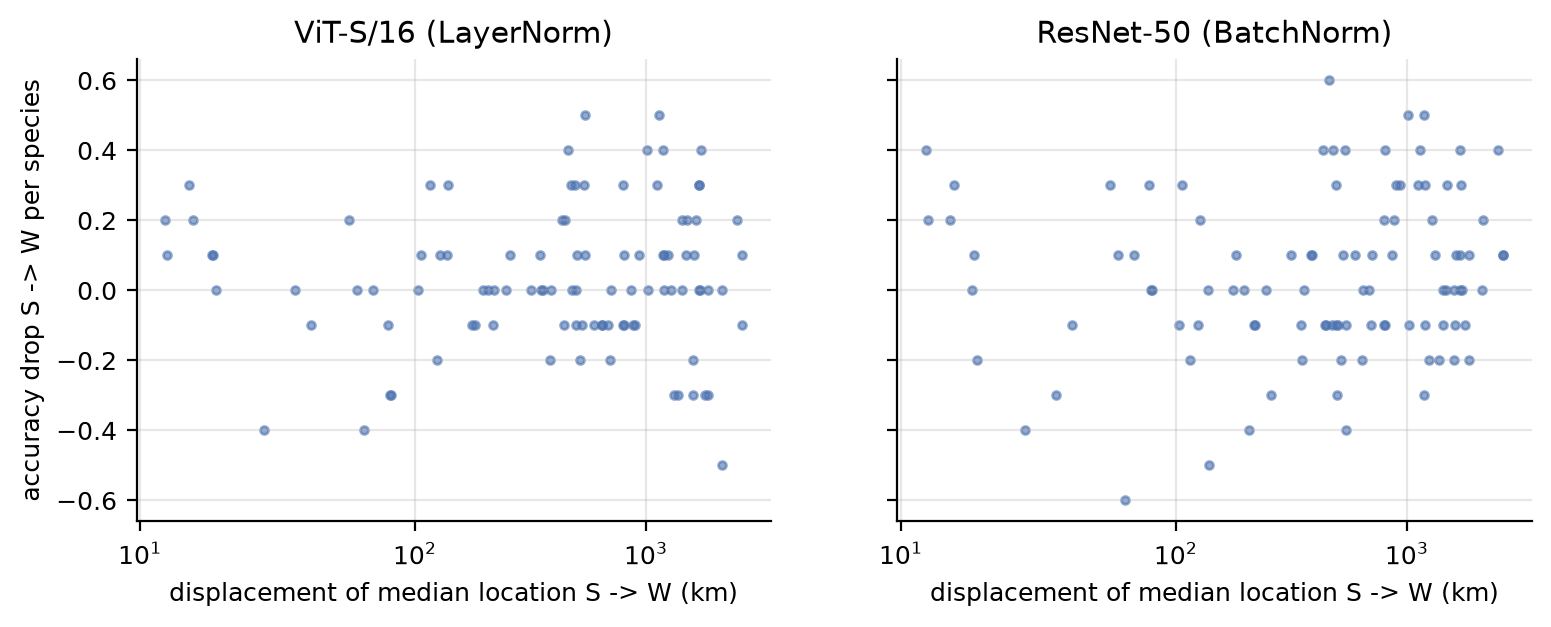

In [10]:
fig('05_why_species_displacement')